# Visualizacao e comparacao das bases NASA POWER, INPE e SONDA

Este notebook organiza as series em resolucao horaria, produz figuras de evolucao temporal por fonte, compara as variaveis nos intervalos simultaneamente disponiveis e salva tabelas estatisticas.

A comparacao de radiacao usa NASA POWER, INPE e SONDA-SD. Temperatura e umidade usam NASA POWER, INPE e os campos presentes nos arquivos SONDA-MD. Antes de interpretar comparacoes instantaneas, confirme a referencia de horario da base INPE; NASA POWER esta em UTC e a pagina da estacao CPA informa UTC para os dados solarimetricos SONDA.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['savefig.dpi'] = 180

def encontrar_pasta_2026(inicio=Path.cwd()):
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        candidata = pasta / '2026'
        if candidata.exists():
            return candidata
    raise FileNotFoundError('Nao foi encontrada a pasta 2026 a partir do diretorio atual.')

PASTA_2026 = encontrar_pasta_2026()
PASTA_NASA = PASTA_2026 / 'dados_brutos_nasa_power'
PASTA_SONDA = PASTA_2026 / 'Dados SONDA'
ARQUIVO_INPE = PASTA_2026 / 'wave_analisys_inpe' / 'dados_tratados' / 'inpe_onehour_tratado.csv'
PASTA_SONDA_TRATADA = PASTA_2026 / 'dados_tratados_sonda'
PASTA_SAIDA = PASTA_2026 / 'visualizacoes_comparativas_bases'
PASTA_DADOS = PASTA_SAIDA / 'dados_padronizados'
PASTA_FONTE = PASTA_SAIDA / 'figuras_por_fonte'
PASTA_COMPARACAO = PASTA_SAIDA / 'comparacao_entre_fontes'
PASTA_TABELAS = PASTA_SAIDA / 'tabelas'
for pasta in (PASTA_DADOS, PASTA_FONTE, PASTA_COMPARACAO, PASTA_TABELAS):
    pasta.mkdir(parents=True, exist_ok=True)

# Ajuste somente se a verificacao documental indicar diferenca de fuso entre as fontes.
DESLOCAMENTOS_HORAS = {'nasa': 0, 'inpe': 0, 'sonda_md': 0, 'sonda_sd': 0}
INVALIDOS = [-9999, -999, -6999, 7999, 9999]
FREQUENCIA_VISUAL = 'D'  # media diaria para figuras legiveis em series longas

print(f'Pasta de saida: {PASTA_SAIDA}')

Pasta de saida: C:\Users\Windows\OneDrive\Documentos\Iniciação Cientifica - INPE\2026\visualizacoes_comparativas_bases


In [2]:
def converter_numericas(df, colunas):
    for coluna in colunas:
        if coluna in df.columns:
            df[coluna] = pd.to_numeric(df[coluna], errors='coerce').replace(INVALIDOS, np.nan)
    return df

def ler_nasa_power():
    partes = []
    for arquivo in sorted(PASTA_NASA.glob('*.csv')):
        linhas = arquivo.read_text(encoding='utf-8').splitlines()
        cabecalho = next(i for i, linha in enumerate(linhas) if linha.startswith('YEAR,'))
        bruto = pd.read_csv(arquivo, skiprows=cabecalho)
        bruto = converter_numericas(bruto, ['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M'])
        bruto['data_hora'] = pd.to_datetime(
            bruto[['YEAR', 'MO', 'DY', 'HR']].rename(
                columns={'YEAR': 'year', 'MO': 'month', 'DY': 'day', 'HR': 'hour'}
            )
        )
        partes.append(bruto[['data_hora', 'ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M']])

    dados = pd.concat(partes, ignore_index=True).rename(columns={
        'ALLSKY_SFC_SW_DWN': 'radiacao_onda_curta',
        'T2M': 'temperatura',
        'RH2M': 'umidade_relativa',
    })
    dados['data_hora'] += pd.Timedelta(hours=DESLOCAMENTOS_HORAS['nasa'])
    return dados.sort_values('data_hora').drop_duplicates('data_hora').reset_index(drop=True)

def ler_inpe():
    dados = pd.read_csv(ARQUIVO_INPE)
    dados['data_hora'] = pd.to_datetime(dados['data_hora'], errors='coerce')
    dados = converter_numericas(dados, ['radiacao_onda_curta', 'temperatura', 'umidade_relativa'])
    dados['data_hora'] += pd.Timedelta(hours=DESLOCAMENTOS_HORAS['inpe'])
    return dados.dropna(subset=['data_hora']).sort_values('data_hora').drop_duplicates('data_hora').reset_index(drop=True)

def ler_sonda_md():
    arquivos = sorted(PASTA_SONDA_TRATADA.glob('sonda_horario_*.csv'))
    if not arquivos:
        raise FileNotFoundError('Arquivos horarios SONDA-MD nao encontrados em dados_tratados_sonda.')
    dados = pd.concat((pd.read_csv(arquivo) for arquivo in arquivos), ignore_index=True)
    dados['data_hora'] = pd.to_datetime(dados['data_hora'], errors='coerce')
    colunas = ['tp_sfc', 'humid', 'press', 'rain', 'ws10_avg', 'wd10_avg', 'n_obs_hora']
    dados = converter_numericas(dados, colunas).rename(columns={
        'tp_sfc': 'temperatura', 'humid': 'umidade_relativa',
        'press': 'pressao', 'rain': 'chuva',
        'ws10_avg': 'velocidade_vento', 'wd10_avg': 'direcao_vento',
    })
    dados['data_hora'] += pd.Timedelta(hours=DESLOCAMENTOS_HORAS['sonda_md'])
    return dados.dropna(subset=['data_hora']).sort_values('data_hora').drop_duplicates('data_hora').reset_index(drop=True)

def ler_sonda_sd_horaria():
    colunas_sd = ['glo_avg', 'dif_avg', 'dir_avg', 'lw_raw_avg', 'lw_calc_avg', 'par_avg', 'lux_avg', 'tilt_avg']
    partes = []
    for arquivo in sorted(PASTA_SONDA.rglob('*_SD.dat')):
        bruto = pd.read_csv(arquivo, skiprows=[0, 2, 3], low_memory=False)
        disponiveis = [coluna for coluna in colunas_sd if coluna in bruto.columns]
        bruto = bruto[['TIMESTAMP', *disponiveis]].copy()
        bruto['TIMESTAMP'] = pd.to_datetime(bruto['TIMESTAMP'], errors='coerce')
        bruto = converter_numericas(bruto, disponiveis).dropna(subset=['TIMESTAMP'])
        partes.append(bruto)

    dados = pd.concat(partes, ignore_index=True).rename(columns={'TIMESTAMP': 'data_hora'})
    dados = dados.sort_values('data_hora').drop_duplicates('data_hora')
    dados['data_hora'] += pd.Timedelta(hours=DESLOCAMENTOS_HORAS['sonda_sd'])
    dados['hora'] = dados['data_hora'].dt.floor('h')
    return dados.groupby('hora', as_index=False)[colunas_sd].mean().rename(columns={'hora': 'data_hora'})

nasa = ler_nasa_power()
inpe = ler_inpe()
sonda_md = ler_sonda_md()
sonda_sd = ler_sonda_sd_horaria()

for nome, dados in {'nasa': nasa, 'inpe': inpe, 'sonda_md': sonda_md, 'sonda_sd': sonda_sd}.items():
    dados.to_csv(PASTA_DADOS / f'{nome}_horario_padronizado.csv', index=False)
    print(f'{nome:8s}: {len(dados):6d} linhas | {dados.data_hora.min()} a {dados.data_hora.max()}')

nasa    :  17568 linhas | 2024-01-05 00:00:00 a 2026-01-05 23:00:00
inpe    :   4643 linhas | 2024-05-08 12:00:00 a 2025-02-11 14:00:00


sonda_md:  15384 linhas | 2024-05-01 00:00:00 a 2026-01-31 23:00:00


sonda_sd:  30539 linhas | 2023-01-01 00:00:00 a 2026-06-30 23:00:00


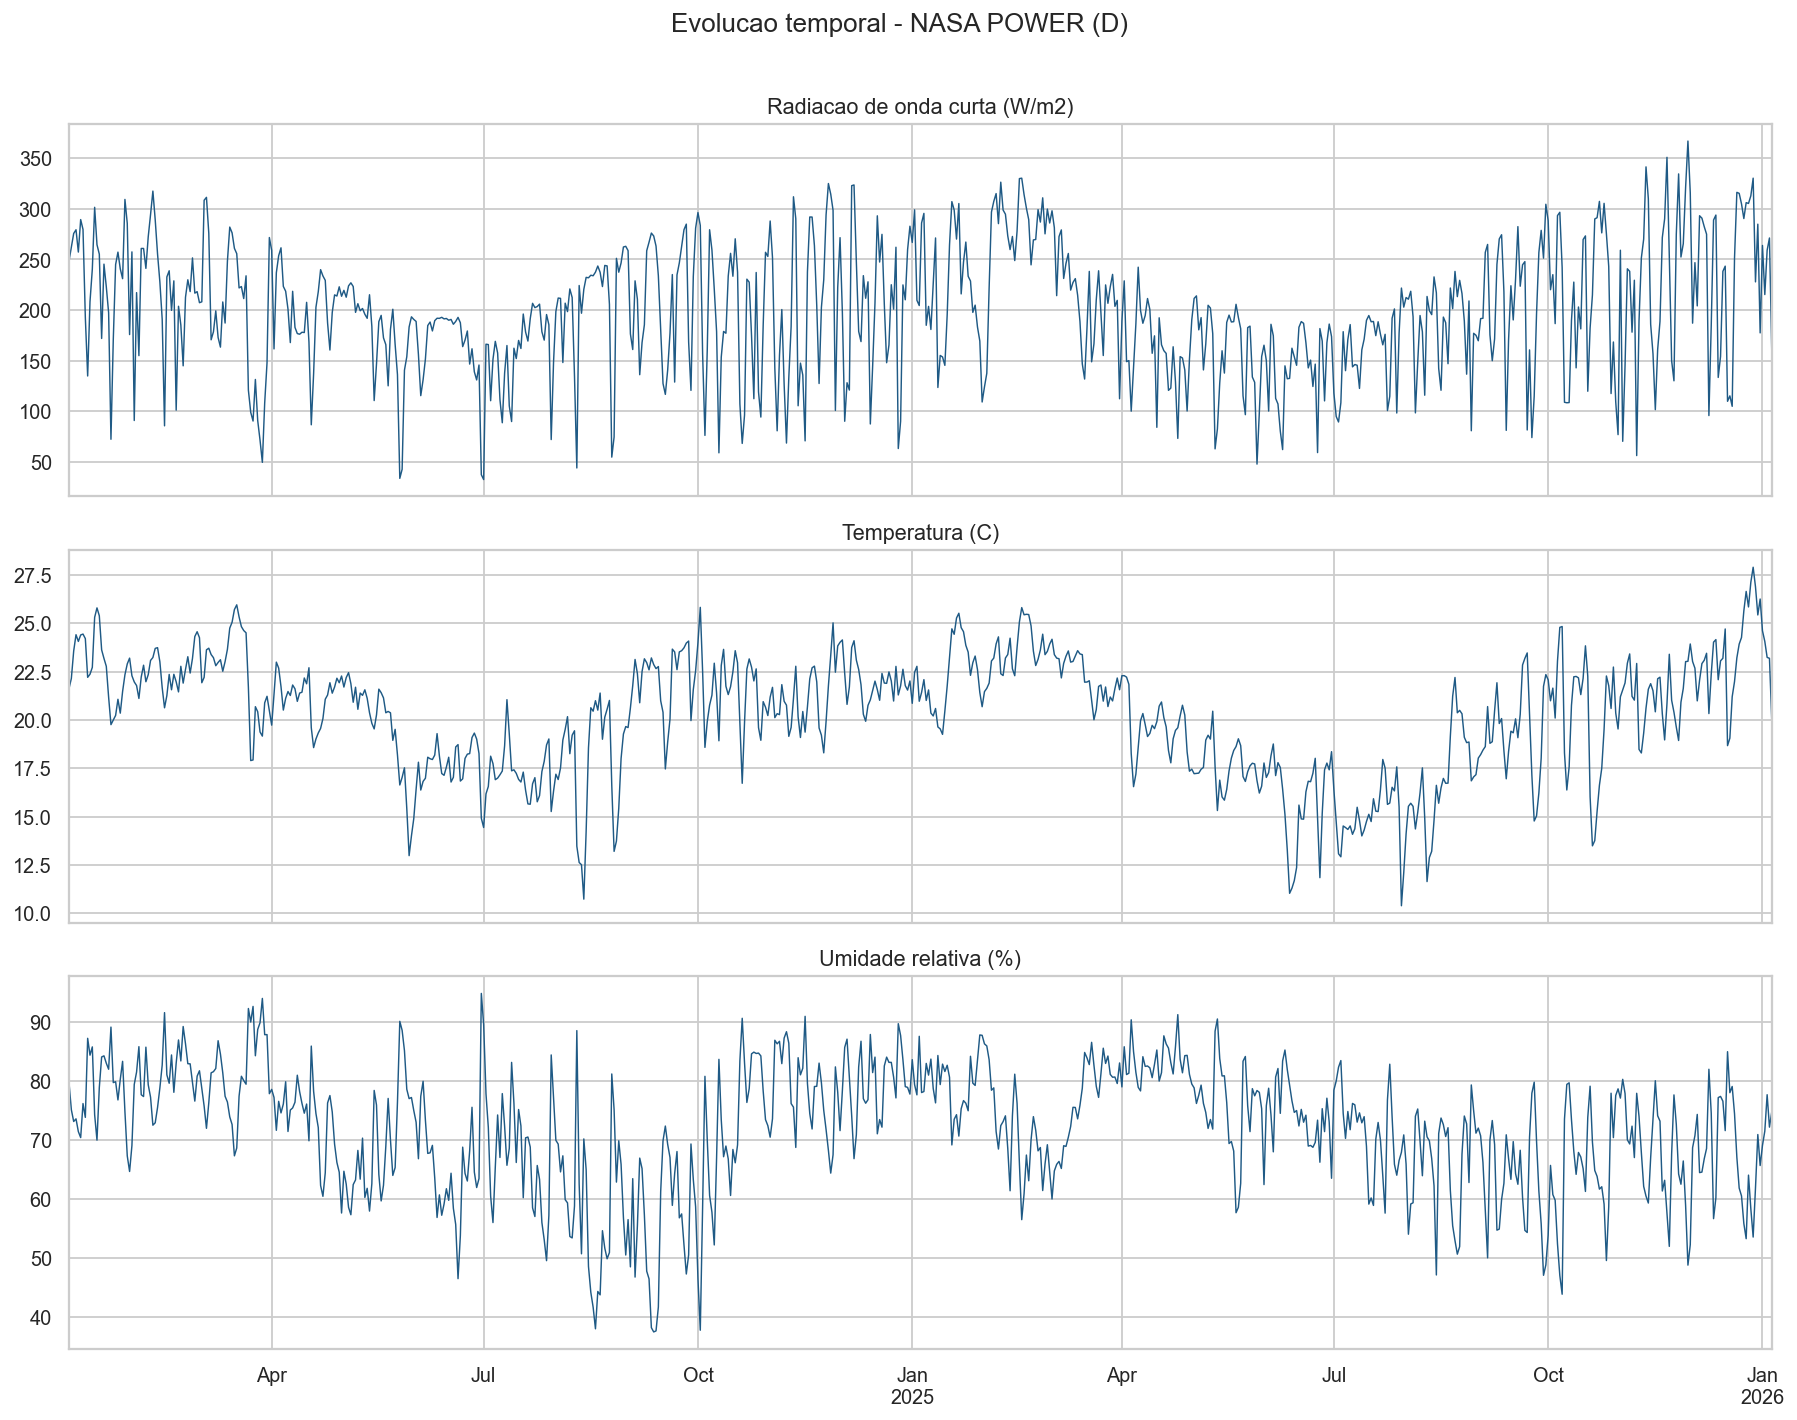

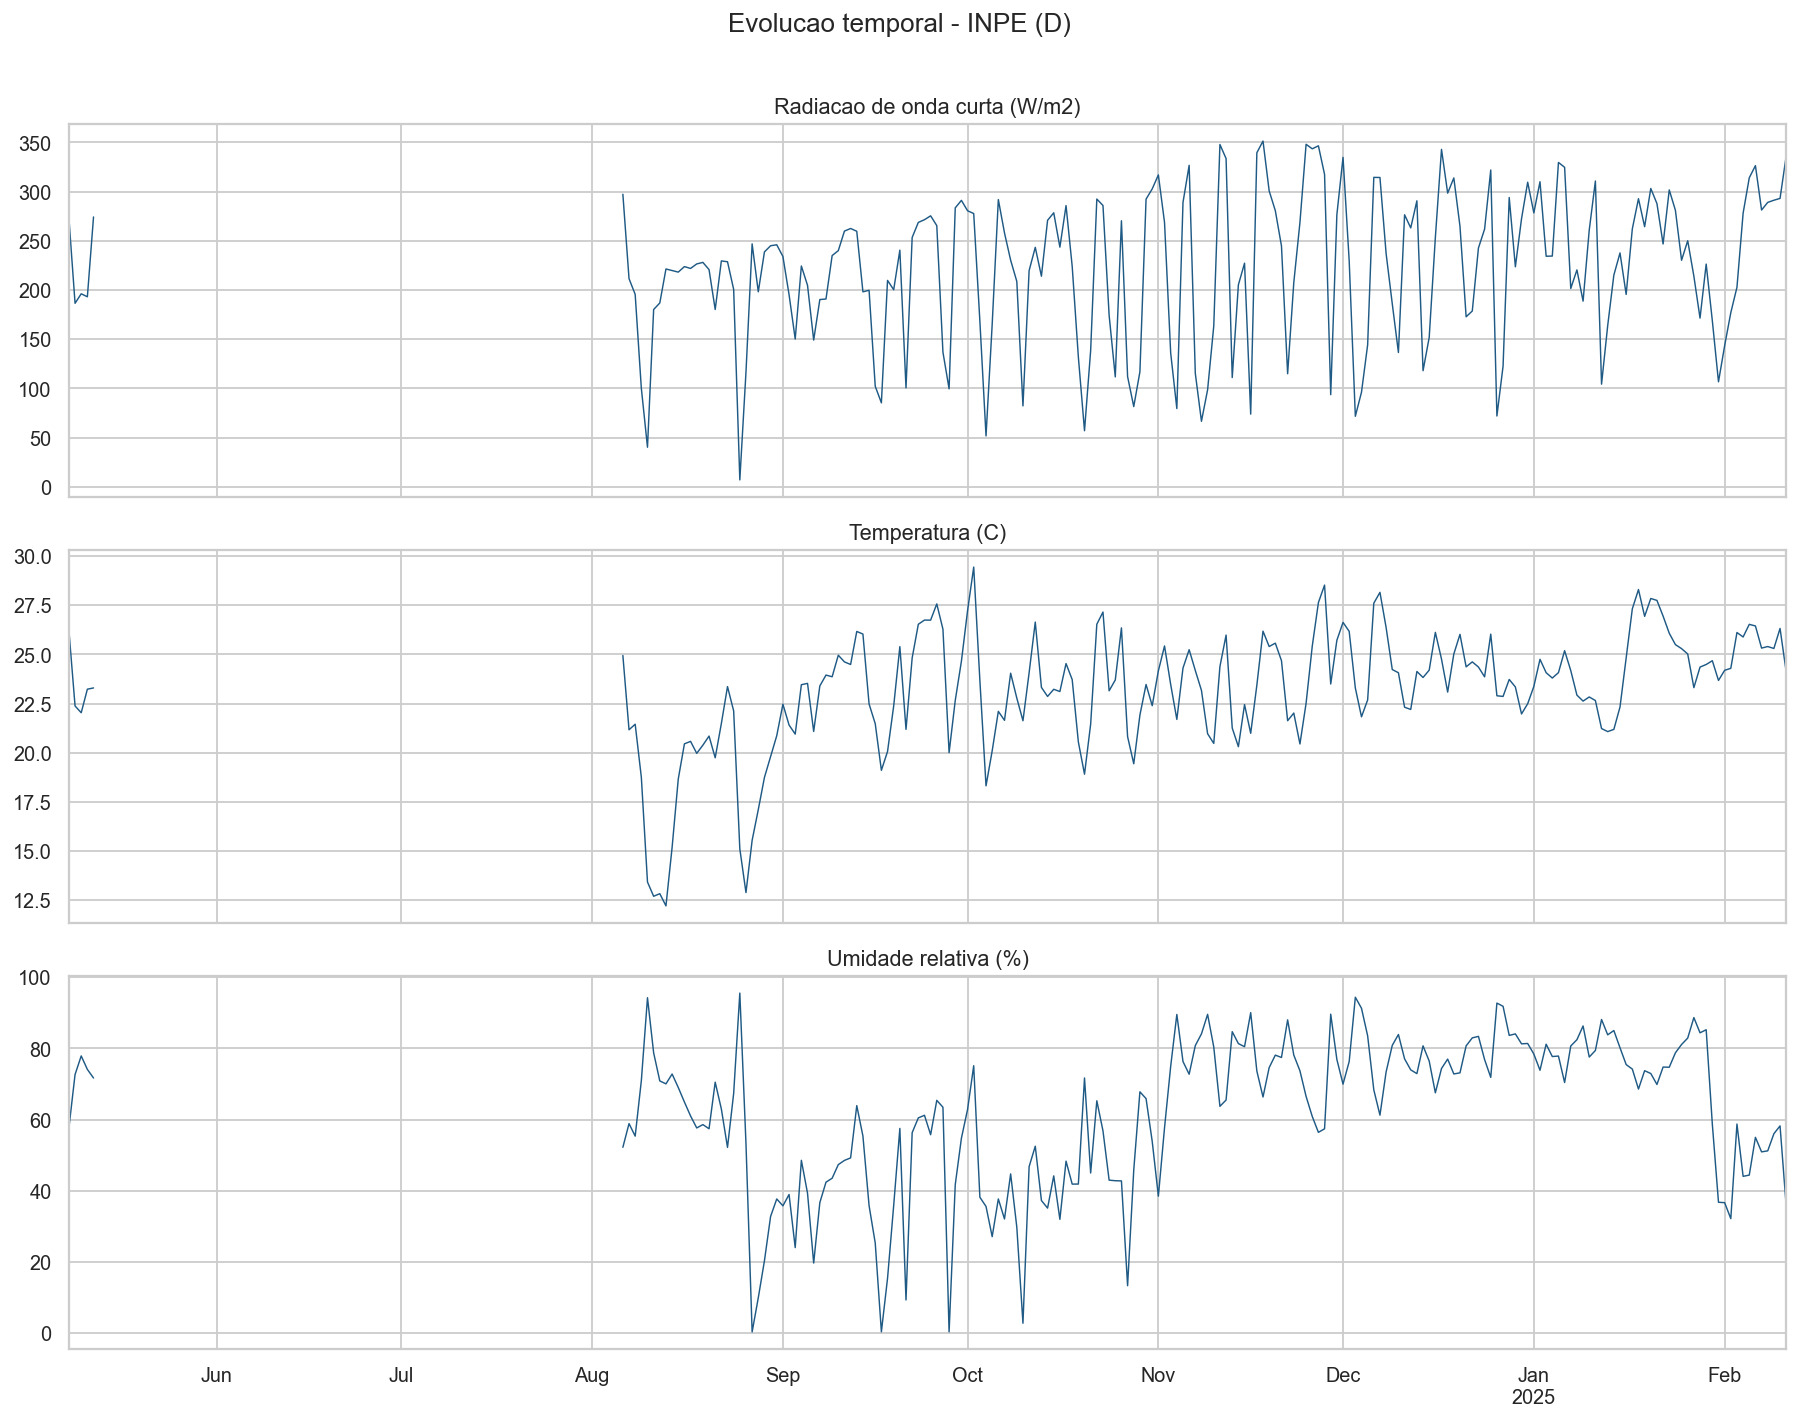

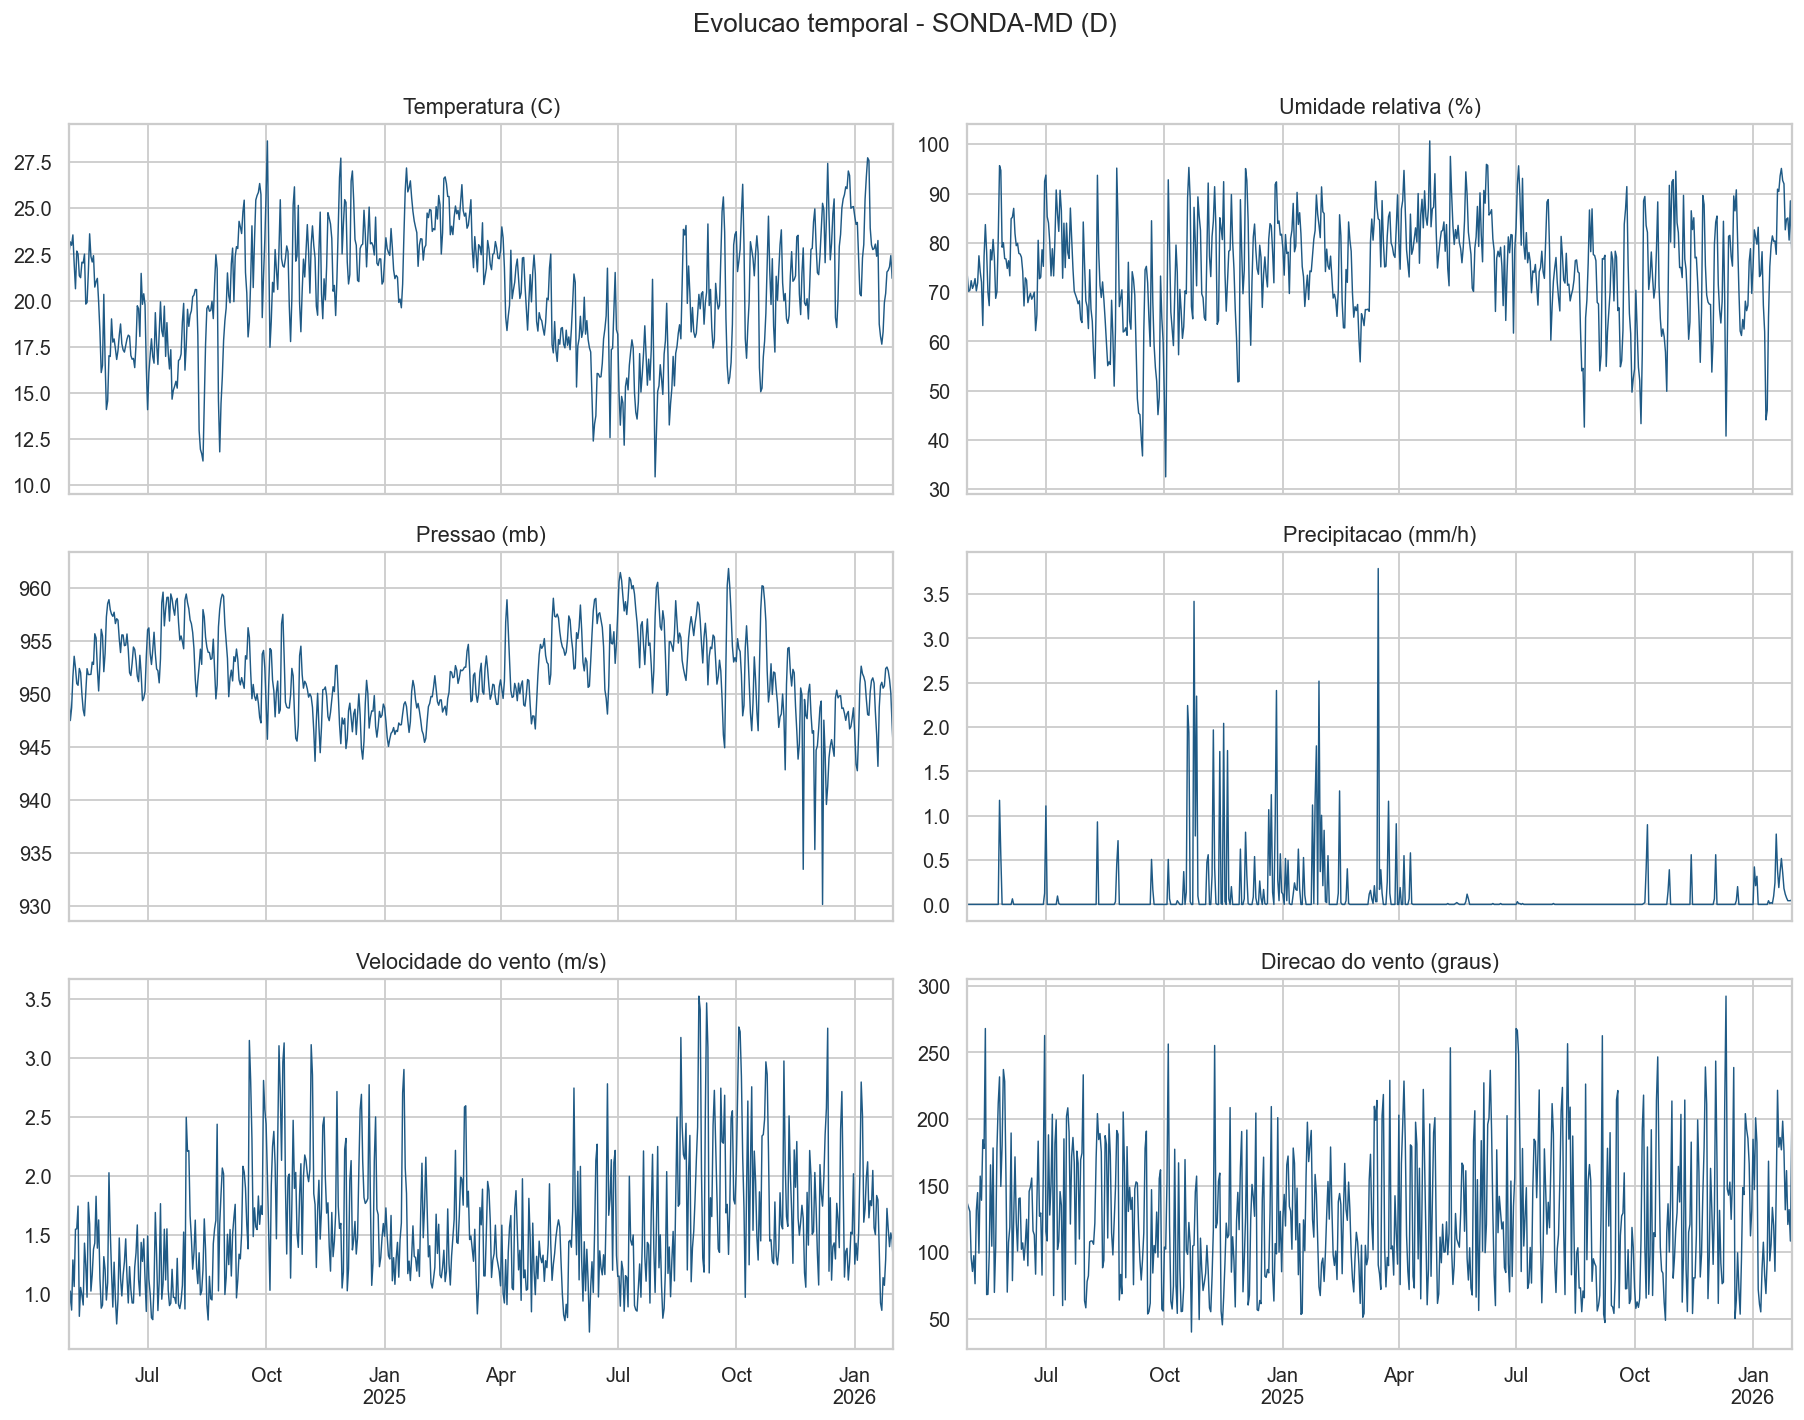

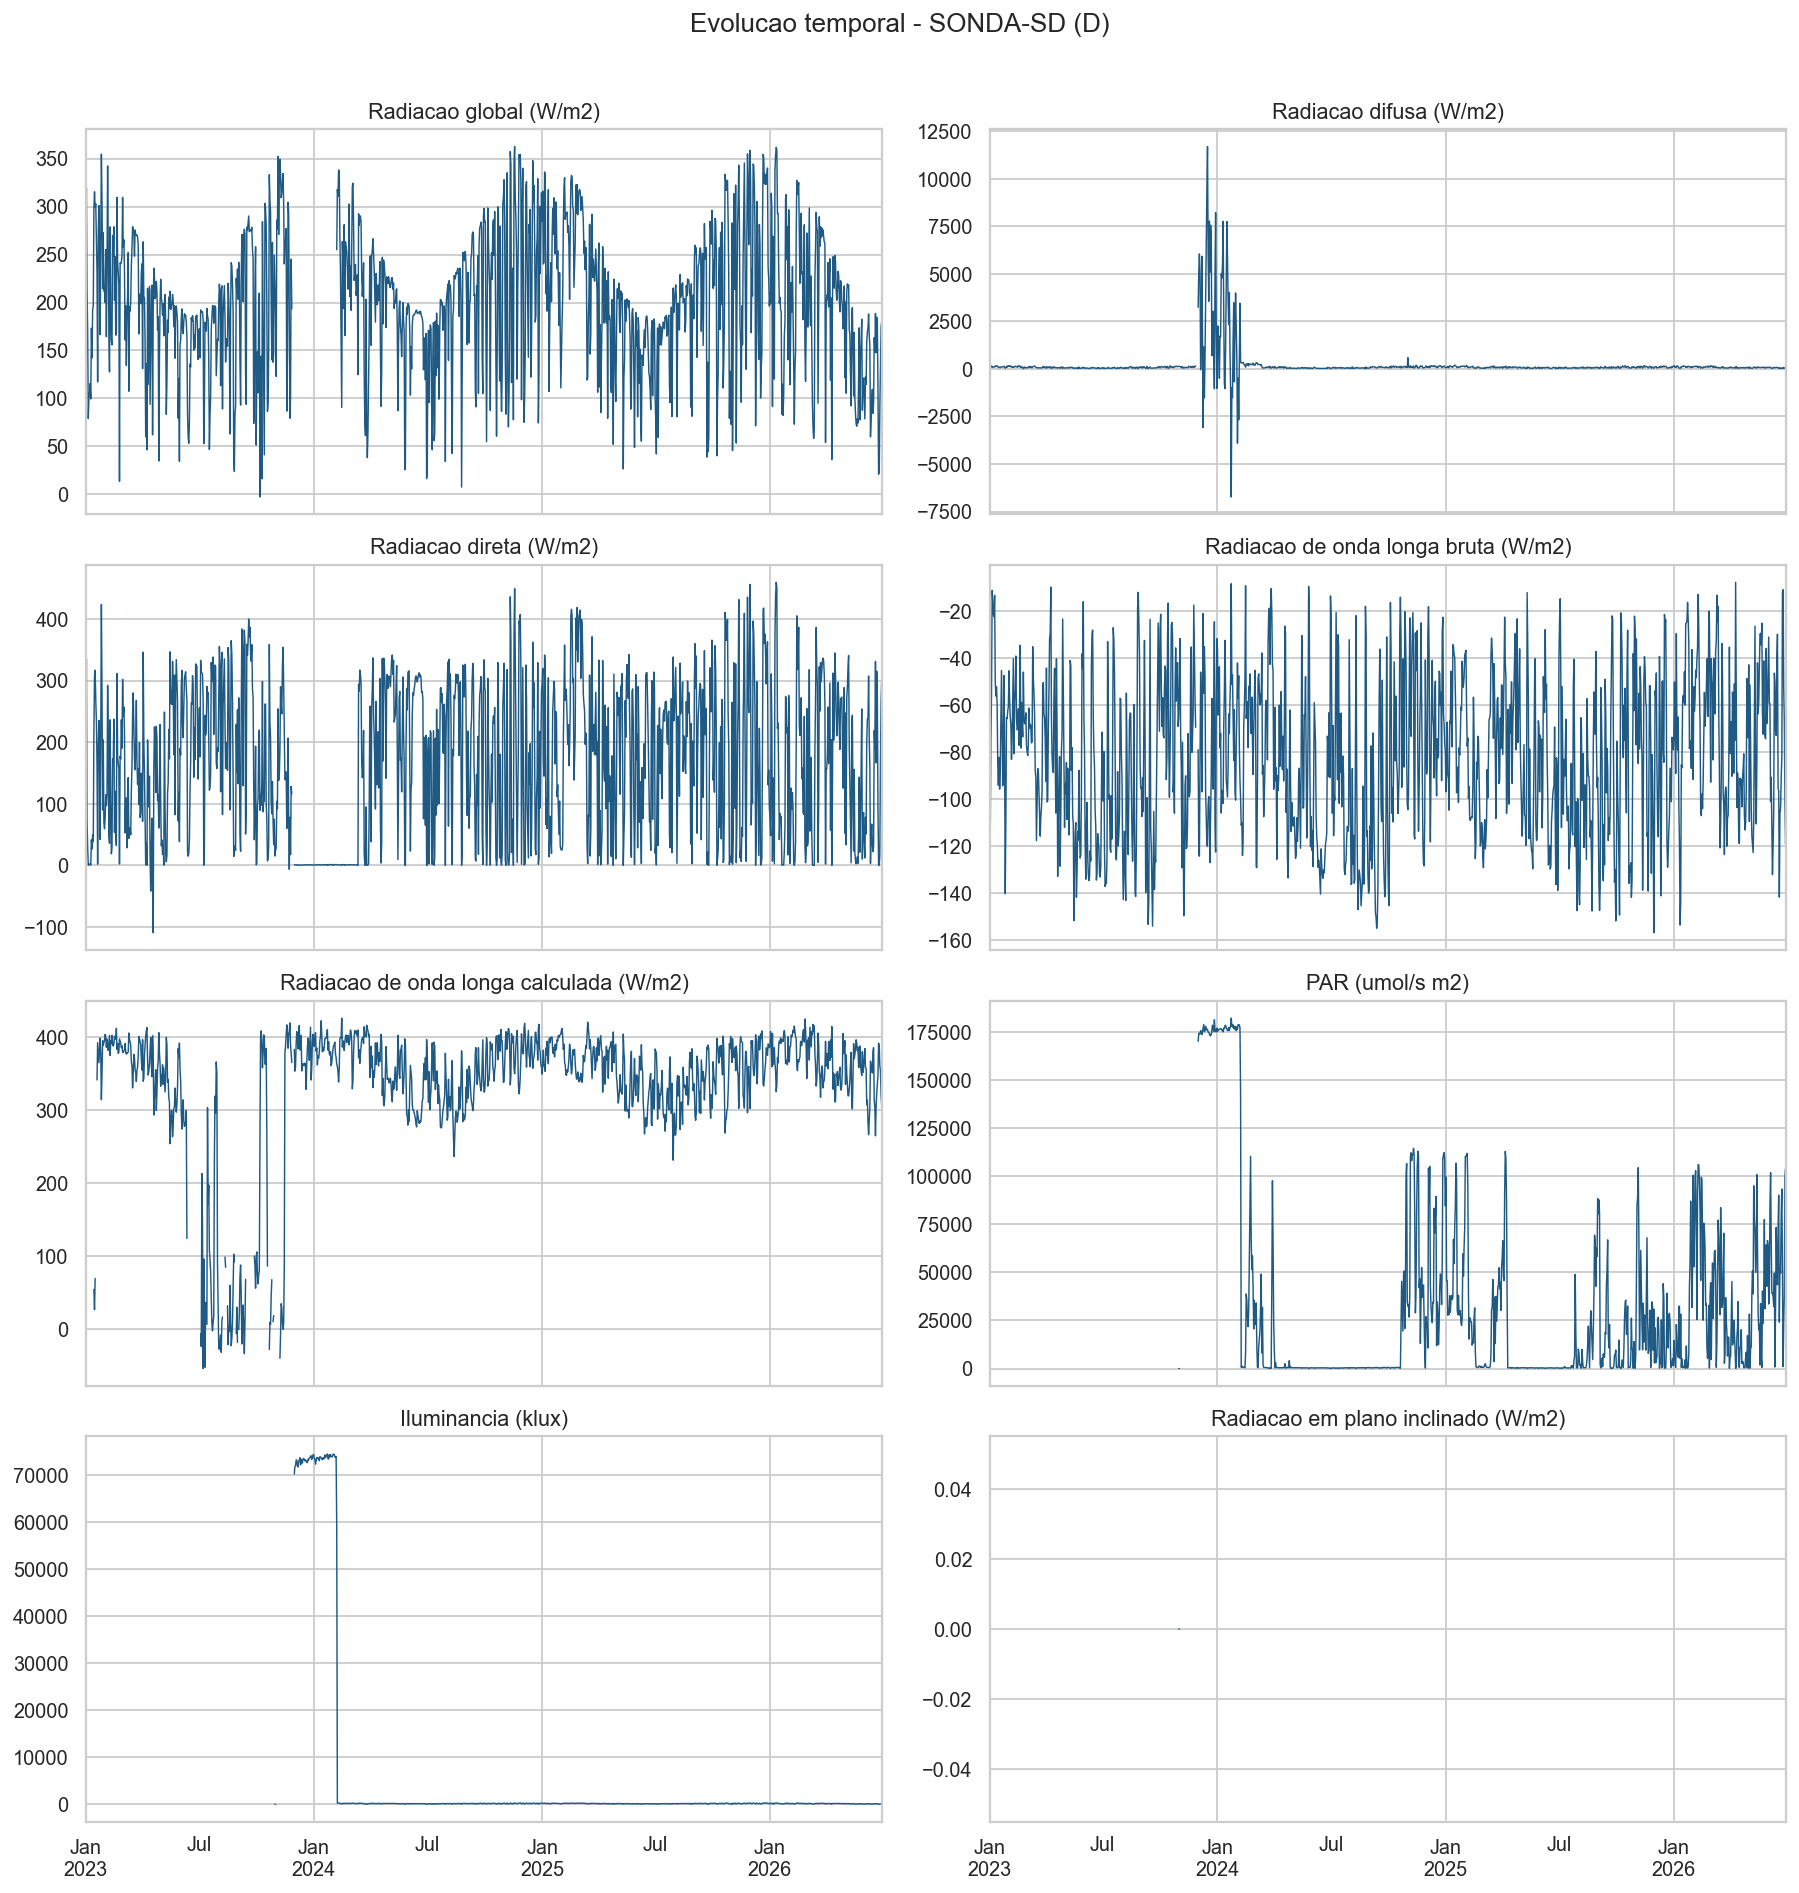

In [3]:
ROTULOS = {
    'radiacao_onda_curta': 'Radiacao de onda curta (W/m2)',
    'glo_avg': 'Radiacao global (W/m2)',
    'dif_avg': 'Radiacao difusa (W/m2)',
    'dir_avg': 'Radiacao direta (W/m2)',
    'lw_raw_avg': 'Radiacao de onda longa bruta (W/m2)',
    'lw_calc_avg': 'Radiacao de onda longa calculada (W/m2)',
    'par_avg': 'PAR (umol/s m2)',
    'lux_avg': 'Iluminancia (klux)',
    'tilt_avg': 'Radiacao em plano inclinado (W/m2)',
    'temperatura': 'Temperatura (C)',
    'umidade_relativa': 'Umidade relativa (%)',
    'pressao': 'Pressao (mb)',
    'chuva': 'Precipitacao (mm/h)',
    'velocidade_vento': 'Velocidade do vento (m/s)',
    'direcao_vento': 'Direcao do vento (graus)',
}

def serie_visual(dados, coluna):
    return dados.set_index('data_hora')[coluna].resample(FREQUENCIA_VISUAL).mean()

def plotar_evolucao(dados, nome, colunas, arquivo, ncol=1):
    colunas = [coluna for coluna in colunas if coluna in dados.columns]
    nlin = int(np.ceil(len(colunas) / ncol))
    fig, eixos = plt.subplots(nlin, ncol, figsize=(14, 3.6 * nlin), sharex=True, squeeze=False)
    for eixo, coluna in zip(eixos.flat, colunas):
        serie_visual(dados, coluna).plot(ax=eixo, color='#1f5a85', linewidth=0.8)
        eixo.set_title(ROTULOS.get(coluna, coluna))
        eixo.set_xlabel('')
        eixo.set_ylabel('')
    for eixo in eixos.flat[len(colunas):]:
        eixo.remove()
    fig.suptitle(f'Evolucao temporal - {nome} ({FREQUENCIA_VISUAL})', y=1.01)
    fig.tight_layout()
    fig.savefig(arquivo, bbox_inches='tight')
    plt.show()
    plt.close(fig)

plotar_evolucao(nasa, 'NASA POWER', ['radiacao_onda_curta', 'temperatura', 'umidade_relativa'], PASTA_FONTE / 'nasa_power_evolucao.png')
plotar_evolucao(inpe, 'INPE', ['radiacao_onda_curta', 'temperatura', 'umidade_relativa'], PASTA_FONTE / 'inpe_evolucao.png')
plotar_evolucao(sonda_md, 'SONDA-MD', ['temperatura', 'umidade_relativa', 'pressao', 'chuva', 'velocidade_vento', 'direcao_vento'], PASTA_FONTE / 'sonda_md_evolucao.png', ncol=2)
plotar_evolucao(sonda_sd, 'SONDA-SD', ['glo_avg', 'dif_avg', 'dir_avg', 'lw_raw_avg', 'lw_calc_avg', 'par_avg', 'lux_avg', 'tilt_avg'], PASTA_FONTE / 'sonda_sd_evolucao.png', ncol=2)

## Comparacao entre fontes

Cada comparacao usa apenas horarios em que todas as fontes do grupo possuem valor valido. A radiacao da NASA POWER e fornecida no arquivo como energia horaria em Wh/m2; para uma janela de uma hora, seu valor numerico corresponde a potencia media em W/m2 no intervalo.

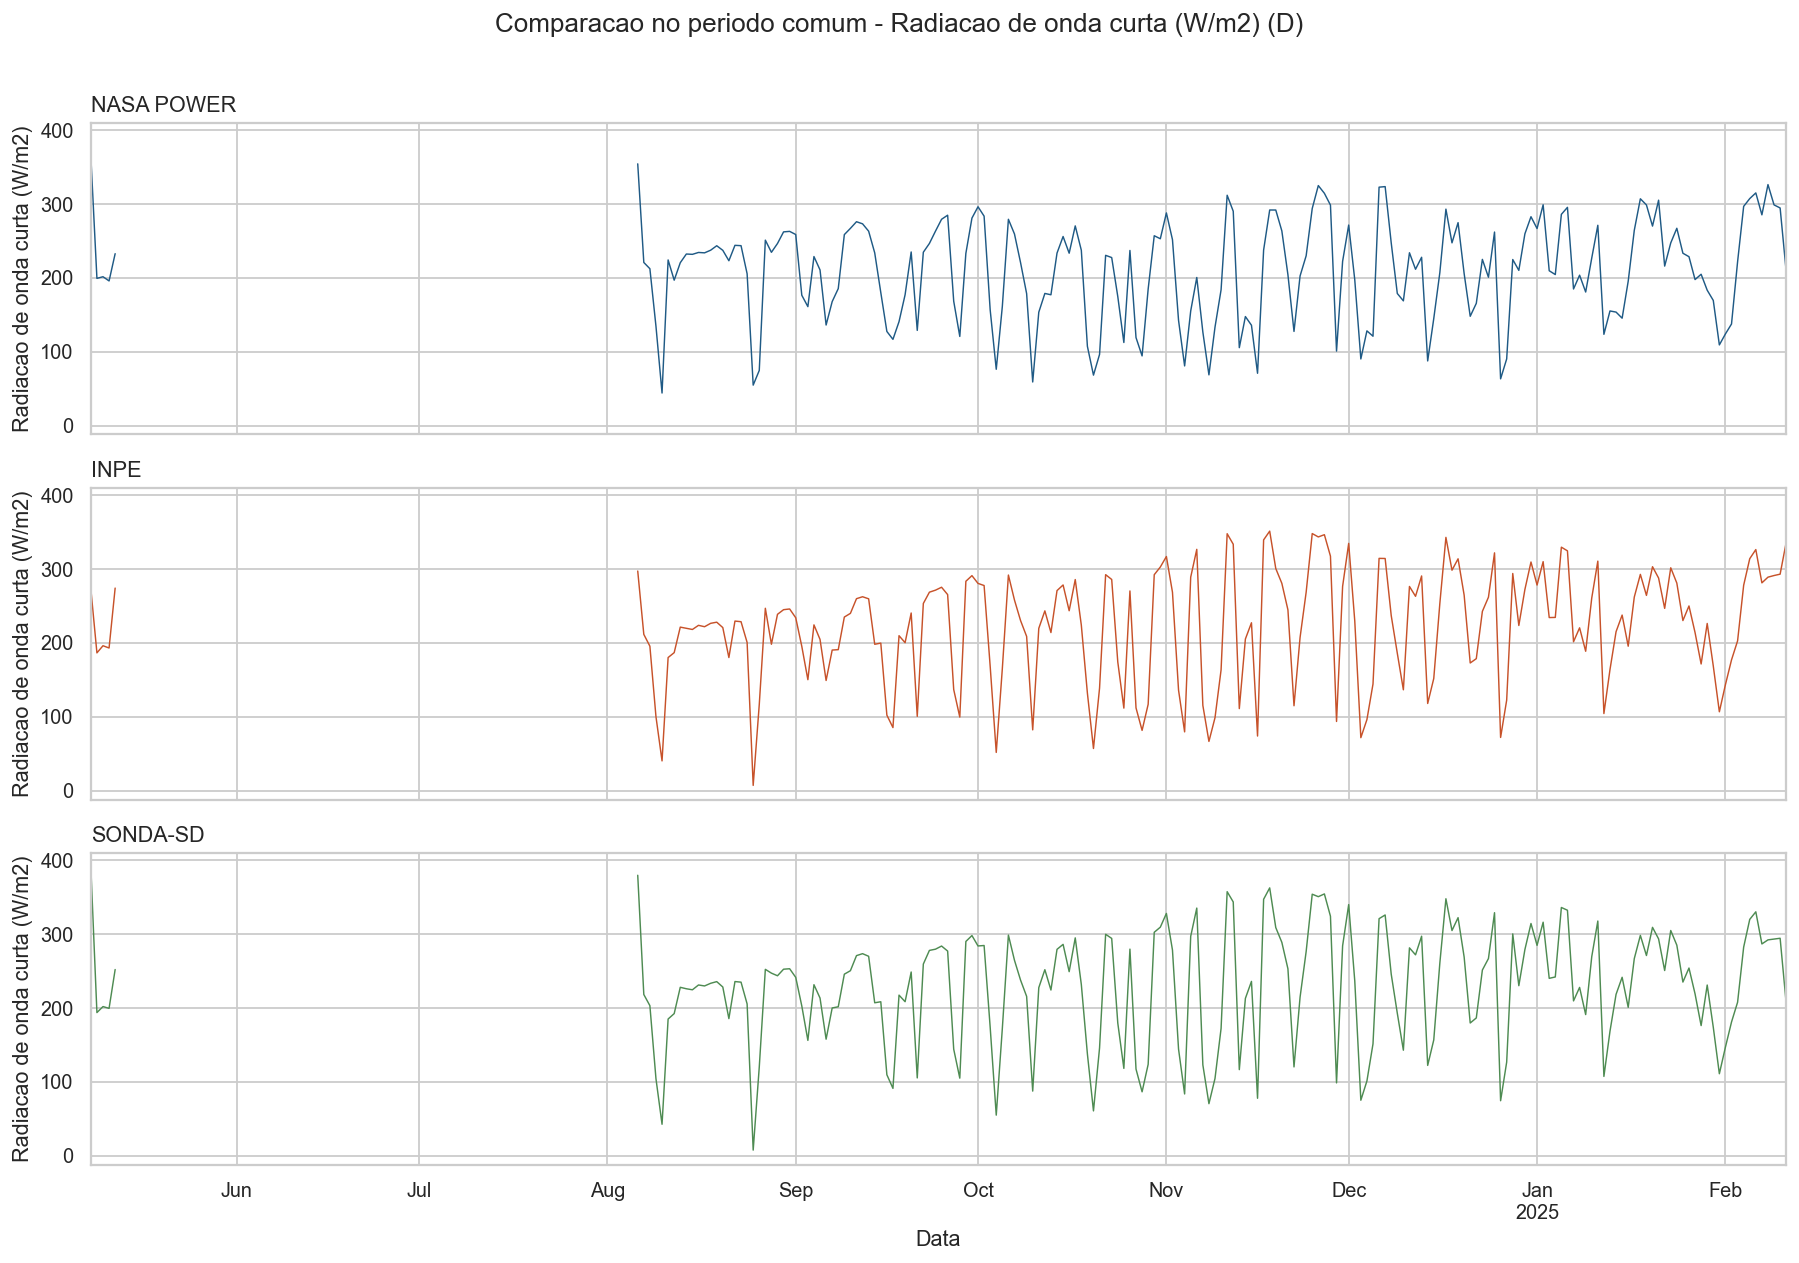

radiacao_onda_curta: 2024-05-08 12:00:00 a 2025-02-11 14:00:00 | 4640 horas comuns


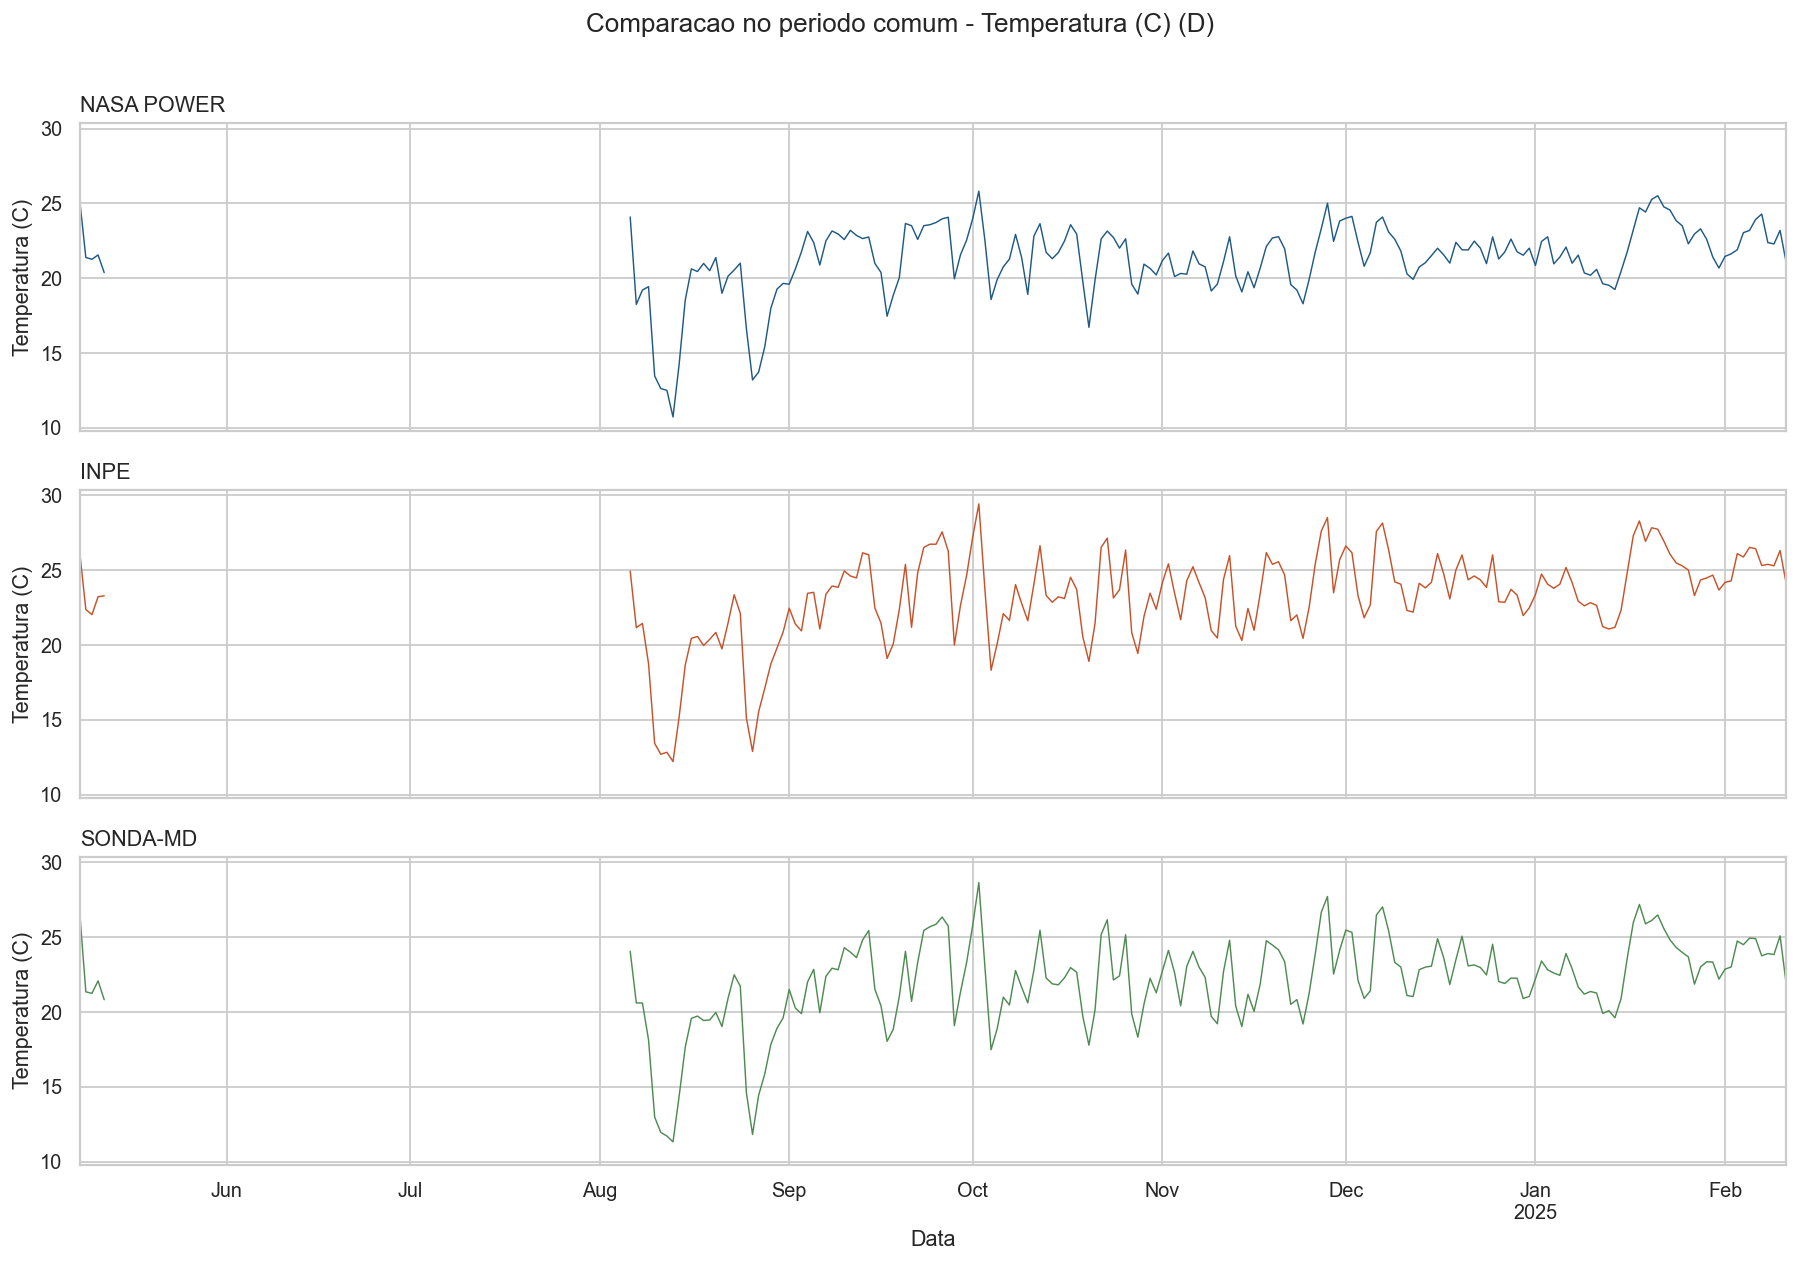

temperatura: 2024-05-08 12:00:00 a 2025-02-11 14:00:00 | 4643 horas comuns


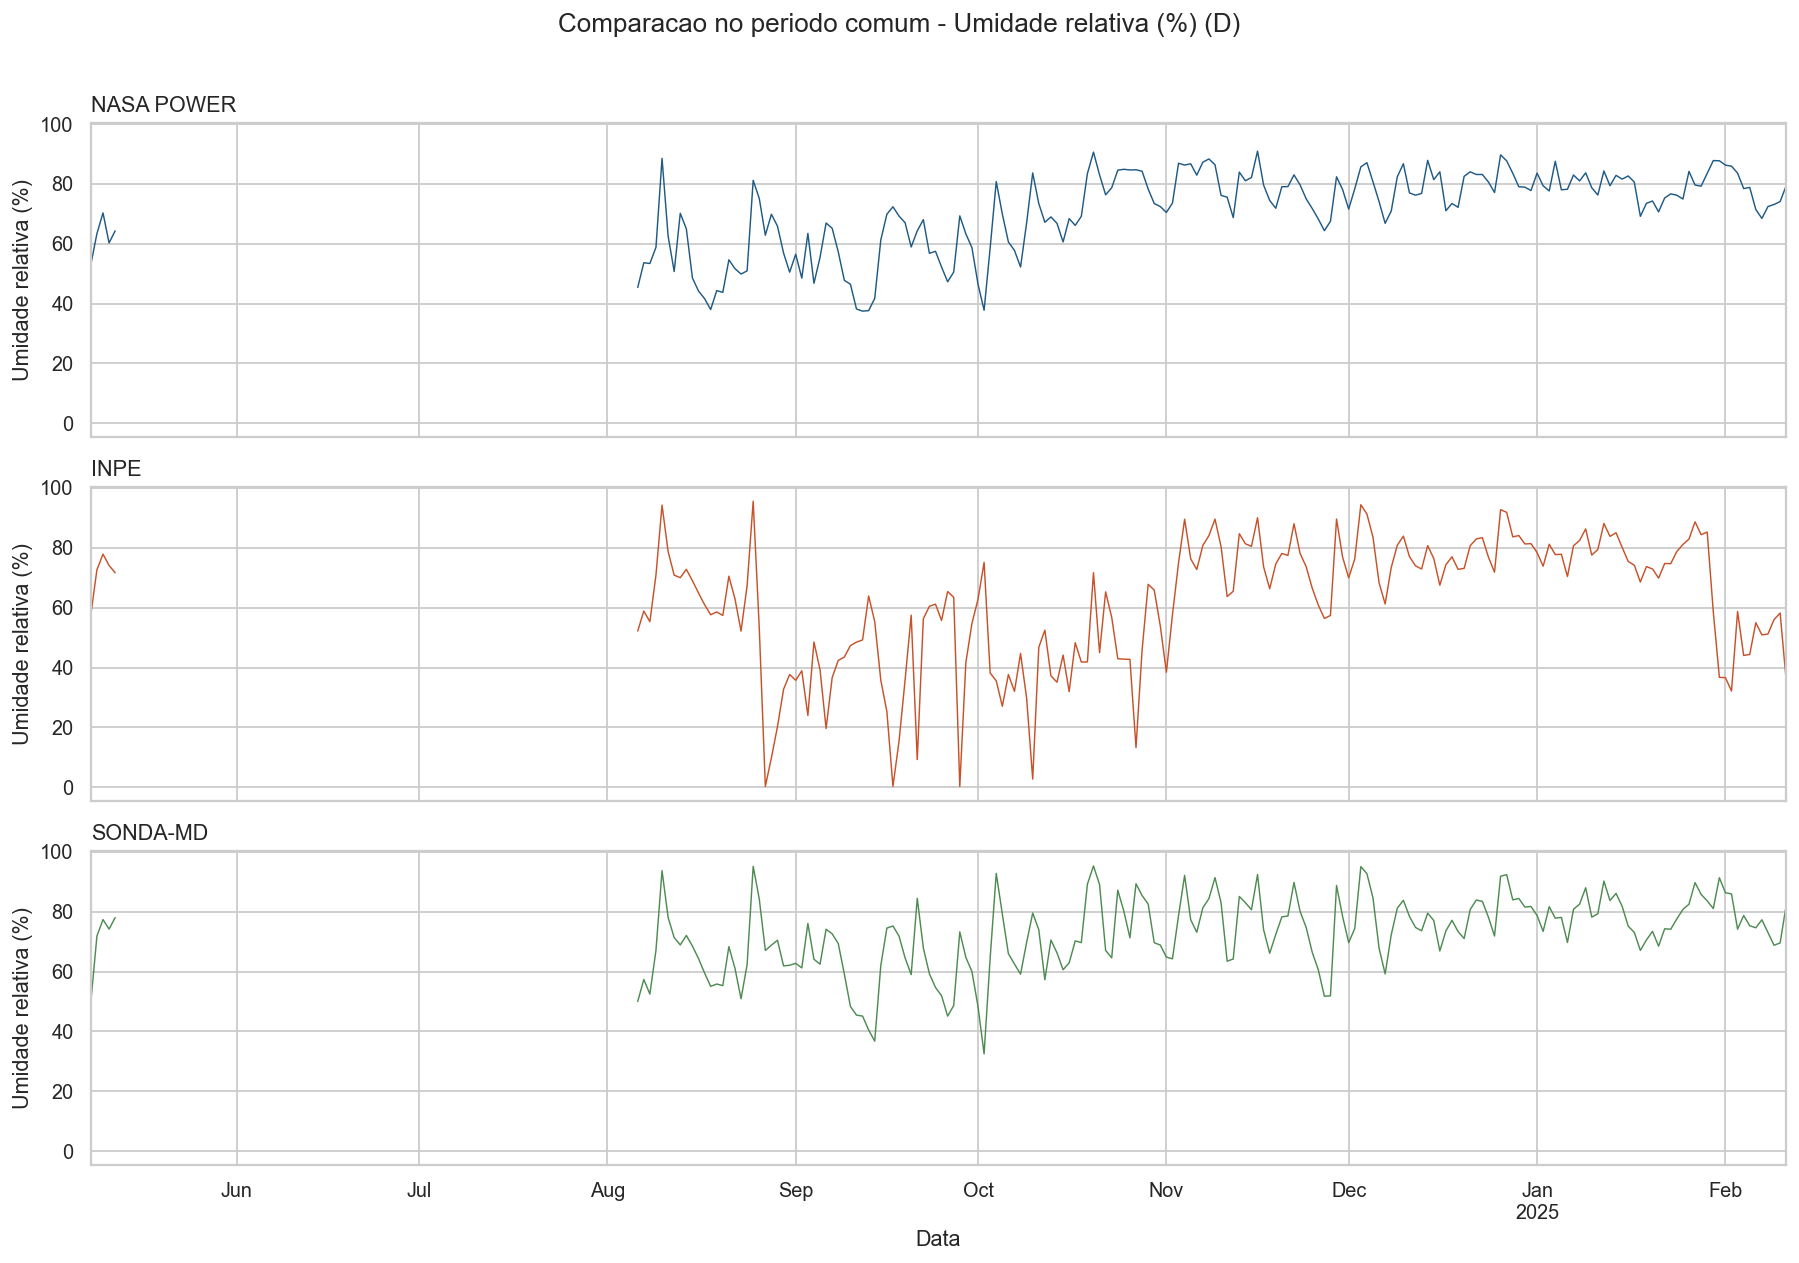

umidade_relativa: 2024-05-08 12:00:00 a 2025-02-11 14:00:00 | 4643 horas comuns


,variavel,fonte,n_horas_comuns,inicio_comum,fim_comum,media,mediana,desvio_padrao,minimo,maximo,percentil_25,percentil_75
0,radiacao_onda_curta,NASA POWER,4640,2024-05-08 12:00:00,2025-02-11 14:00:00,209.859,18.355,285.628,0.000,1047.850,0.000,389.350
1,radiacao_onda_curta,INPE,4640,2024-05-08 12:00:00,2025-02-11 14:00:00,221.715,15.480,313.666,0.000,1097.000,0.000,397.200
2,radiacao_onda_curta,SONDA-SD,4640,2024-05-08 12:00:00,2025-02-11 14:00:00,228.414,17.741,320.600,-2.100,1114.992,-0.833,418.947
3,temperatura,NASA POWER,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,21.277,20.300,5.653,3.160,36.450,17.210,25.620
4,temperatura,INPE,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,23.202,22.520,5.217,4.342,38.160,20.060,26.705
5,temperatura,SONDA-MD,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,22.057,21.433,5.017,4.010,36.283,19.029,25.397
6,umidade_relativa,NASA POWER,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,71.142,76.470,24.740,11.660,100.000,51.370,95.150
7,umidade_relativa,INPE,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,61.781,74.550,36.800,0.290,100.500,36.100,93.200
8,umidade_relativa,SONDA-MD,4643,2024-05-08 12:00:00,2025-02-11 14:00:00,72.655,78.488,21.499,12.673,99.088,57.593,90.923


In [4]:
def montar_comparacao(variavel, fontes):
    partes = []
    for rotulo, (dados, coluna) in fontes.items():
        parte = dados[['data_hora', coluna]].rename(columns={coluna: rotulo})
        partes.append(parte)
    comparacao = partes[0]
    for parte in partes[1:]:
        comparacao = comparacao.merge(parte, on='data_hora', how='inner')
    comparacao = comparacao.dropna().sort_values('data_hora').reset_index(drop=True)
    if comparacao.empty:
        raise ValueError(f'Sem periodo comum com dados validos para {variavel}. Verifique os fusos horarios.')
    comparacao.to_csv(PASTA_DADOS / f'comparacao_{variavel}.csv', index=False)
    return comparacao

def estatisticas(comparacao, variavel):
    linhas = []
    for fonte in comparacao.columns.drop('data_hora'):
        serie = comparacao[fonte]
        linhas.append({
            'variavel': variavel, 'fonte': fonte, 'n_horas_comuns': len(serie),
            'inicio_comum': comparacao.data_hora.min(), 'fim_comum': comparacao.data_hora.max(),
            'media': serie.mean(), 'mediana': serie.median(), 'desvio_padrao': serie.std(),
            'minimo': serie.min(), 'maximo': serie.max(),
            'percentil_25': serie.quantile(.25), 'percentil_75': serie.quantile(.75),
        })
    return pd.DataFrame(linhas)

def plotar_comparacao(comparacao, variavel, arquivo):
    fontes = comparacao.columns.drop('data_hora').tolist()
    diario = comparacao.set_index('data_hora')[fontes].resample(FREQUENCIA_VISUAL).mean()
    fig, eixos = plt.subplots(len(fontes), 1, figsize=(14, 3.2 * len(fontes)), sharex=True, sharey=True)
    if len(fontes) == 1:
        eixos = [eixos]
    cores = ['#1f5a85', '#c7522a', '#4e8b52']
    for eixo, fonte, cor in zip(eixos, fontes, cores):
        diario[fonte].plot(ax=eixo, color=cor, linewidth=0.8)
        eixo.set_ylabel(ROTULOS.get(variavel, variavel))
        eixo.set_title(fonte, loc='left')
    eixos[-1].set_xlabel('Data')
    fig.suptitle(f'Comparacao no periodo comum - {ROTULOS.get(variavel, variavel)} ({FREQUENCIA_VISUAL})', y=1.01)
    fig.tight_layout()
    fig.savefig(arquivo, bbox_inches='tight')
    plt.show()
    plt.close(fig)

CONFIGURACOES = {
    'radiacao_onda_curta': {
        'NASA POWER': (nasa, 'radiacao_onda_curta'),
        'INPE': (inpe, 'radiacao_onda_curta'),
        'SONDA-SD': (sonda_sd, 'glo_avg'),
    },
    'temperatura': {
        'NASA POWER': (nasa, 'temperatura'),
        'INPE': (inpe, 'temperatura'),
        'SONDA-MD': (sonda_md, 'temperatura'),
    },
    'umidade_relativa': {
        'NASA POWER': (nasa, 'umidade_relativa'),
        'INPE': (inpe, 'umidade_relativa'),
        'SONDA-MD': (sonda_md, 'umidade_relativa'),
    },
}

tabelas = []
for variavel, fontes in CONFIGURACOES.items():
    comparacao = montar_comparacao(variavel, fontes)
    plotar_comparacao(comparacao, variavel, PASTA_COMPARACAO / f'comparacao_{variavel}.png')
    tabela = estatisticas(comparacao, variavel)
    tabela.to_csv(PASTA_TABELAS / f'estatisticas_{variavel}.csv', index=False)
    tabelas.append(tabela)
    print(f'{variavel}: {comparacao.data_hora.min()} a {comparacao.data_hora.max()} | {len(comparacao)} horas comuns')

tabela_geral = pd.concat(tabelas, ignore_index=True)
tabela_geral.to_csv(PASTA_TABELAS / 'estatisticas_descritivas_todas_as_fontes.csv', index=False)
tabela_geral.round(3)

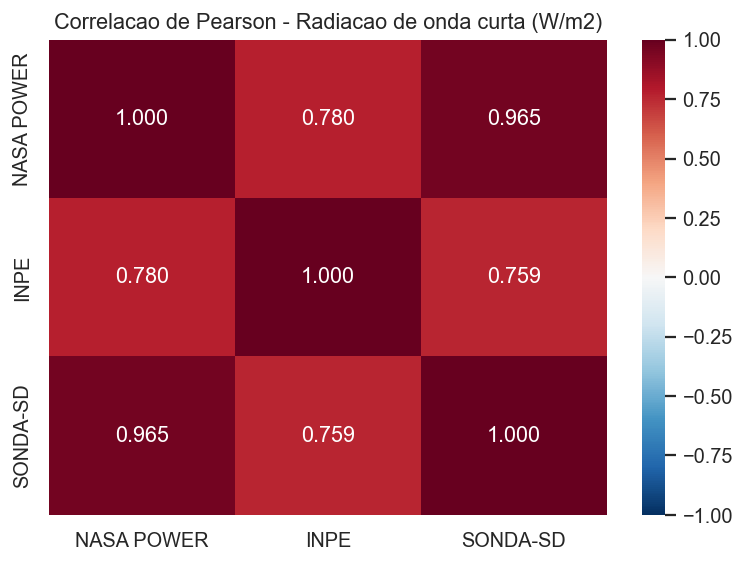

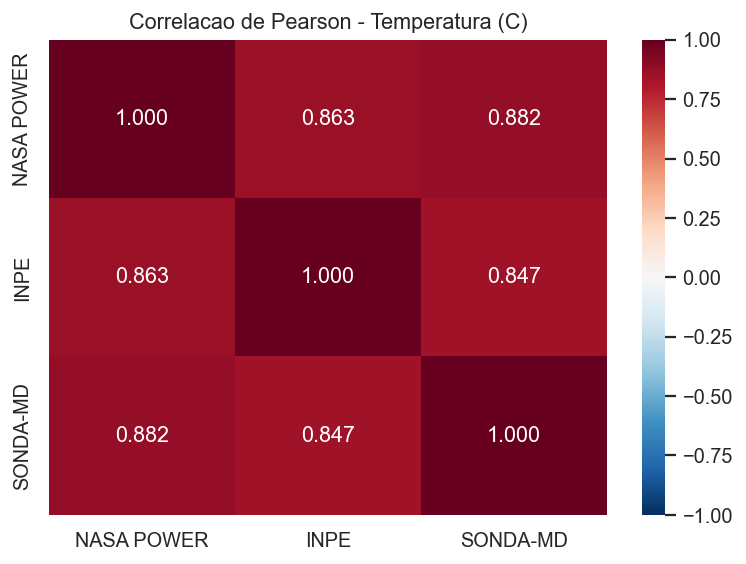

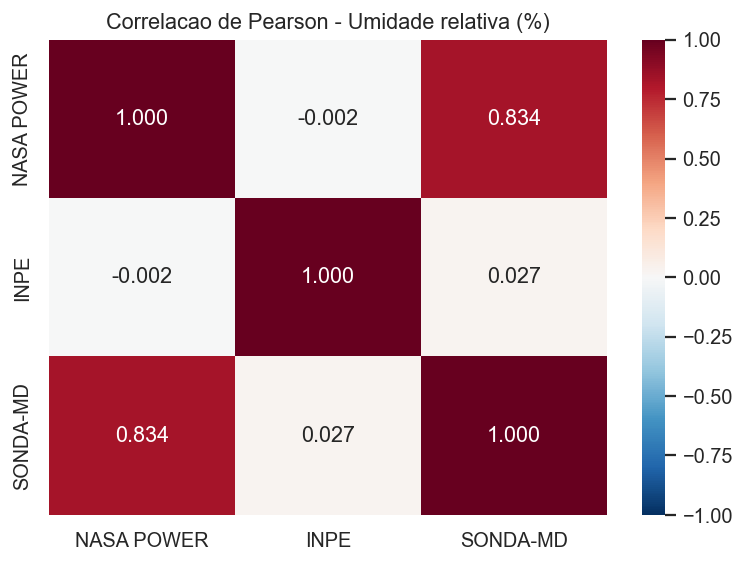

Concluido. Figuras: C:\Users\Windows\OneDrive\Documentos\Iniciação Cientifica - INPE\2026\visualizacoes_comparativas_bases


In [5]:
# Tabelas de correlacao auxiliam a interpretar as diferencas entre as fontes no mesmo periodo.
for variavel, fontes in CONFIGURACOES.items():
    comparacao = pd.read_csv(PASTA_DADOS / f'comparacao_{variavel}.csv', parse_dates=['data_hora'])
    correlacao = comparacao.drop(columns='data_hora').corr(method='pearson')
    correlacao.to_csv(PASTA_TABELAS / f'correlacao_{variavel}.csv')

    fig, ax = plt.subplots(figsize=(6, 4.5))
    sns.heatmap(correlacao, annot=True, fmt='.3f', vmin=-1, vmax=1, cmap='RdBu_r', ax=ax)
    ax.set_title(f'Correlacao de Pearson - {ROTULOS.get(variavel, variavel)}')
    fig.tight_layout()
    fig.savefig(PASTA_COMPARACAO / f'correlacao_{variavel}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Concluido. Figuras:', PASTA_SAIDA)